In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

data = load_digits(as_frame=True)
df = data.frame
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [3]:
from sklearn.tree import DecisionTreeClassifier
model_tree= DecisionTreeClassifier()

In [4]:
param_grid={
    "max_depth": [2,4,6,8,None],
    "min_samples_split":[2,10,30]
}

In [5]:
from sklearn.model_selection import GridSearchCV
grid= GridSearchCV(model_tree,param_grid,cv=5)

In [6]:
grid.fit(X_train,y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 4, ...], 'min_samples_split': [2, 10, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information pri

In [7]:
print(grid.best_params_)
print(grid.best_score_)

{'max_depth': None, 'min_samples_split': 2}
0.8524487030584591


In [8]:
from sklearn.metrics import accuracy_score
y_pred_grid= grid.predict(X_test)
accuracy= accuracy_score(y_test,y_pred_grid)
print(accuracy)

0.825


In [9]:
from sklearn.ensemble import RandomForestClassifier


In [10]:
import time
n_values=[10,50,100,200,300]
acc=[]
times=[]
for n in n_values:
    model_random=RandomForestClassifier(n_estimators=n)
    t1= time.perf_counter()
    model_random.fit(X_train,y_train)
    t2=time.perf_counter()
    y_pred_random=model_random.predict(X_test)
    a= accuracy_score(y_test,y_pred_random)
    acc.append(a)
    times.append(t2-t1)
    print("acc",acc)
    print("time",times)




acc [0.9361111111111111]
time [0.0696068000397645]
acc [0.9361111111111111, 0.9638888888888889]
time [0.0696068000397645, 0.2793635999551043]
acc [0.9361111111111111, 0.9638888888888889, 0.9694444444444444]
time [0.0696068000397645, 0.2793635999551043, 0.4514275000547059]
acc [0.9361111111111111, 0.9638888888888889, 0.9694444444444444, 0.9722222222222222]
time [0.0696068000397645, 0.2793635999551043, 0.4514275000547059, 0.9178632000111975]
acc [0.9361111111111111, 0.9638888888888889, 0.9694444444444444, 0.9722222222222222, 0.9666666666666667]
time [0.0696068000397645, 0.2793635999551043, 0.4514275000547059, 0.9178632000111975, 1.3739969999878667]


In [11]:
import pandas as pd
time_acc=pd.DataFrame({
    "n_estimators":n_values
    ,"accuracy": acc,
    "time":times
})
time_acc

,n_estimators,accuracy,time
0,10,0.936111,0.069607
1,50,0.963889,0.279364
2,100,0.969444,0.451428
3,200,0.972222,0.917863
4,300,0.966667,1.373997


In [12]:
from sklearn.ensemble import GradientBoostingClassifier
accuracy2=[]
learning_rate=[0.01,0.05,0.1,0.3,1.0]
for a in learning_rate:
    model_gradin= GradientBoostingClassifier(n_estimators=100,learning_rate=a)
    model_gradin.fit(X_train,y_train)
    y_pred_gridin=model_gradin.predict(X_test)
    b= accuracy_score(y_test,y_pred_gridin)
    accuracy2.append(b)

In [13]:
print(accuracy2)

[0.8916666666666667, 0.9472222222222222, 0.9555555555555556, 0.9722222222222222, 0.9527777777777777]


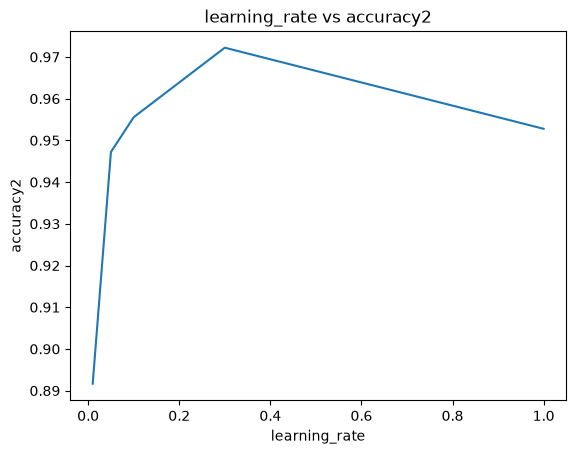

In [14]:
import matplotlib.pyplot as plt
plt.plot(learning_rate,accuracy2)
plt.xlabel("learning_rate")
plt.ylabel("accuracy2")
plt.title("learning_rate vs accuracy2")
plt.show()

In [15]:
from sklearn.datasets import make_moons
x,y = make_moons(n_samples=300,noise=0.2,random_state=42)

In [16]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [17]:
from sklearn.svm import SVC
model_svc= SVC(kernel="poly",degree=3)
model_svc.fit(X_train,y_train)
y_pred_svc = model_svc.predict(X_test)

In [18]:
accuracy_svc = accuracy_score(y_test,y_pred_svc)
accuracy_svc

0.8333333333333334

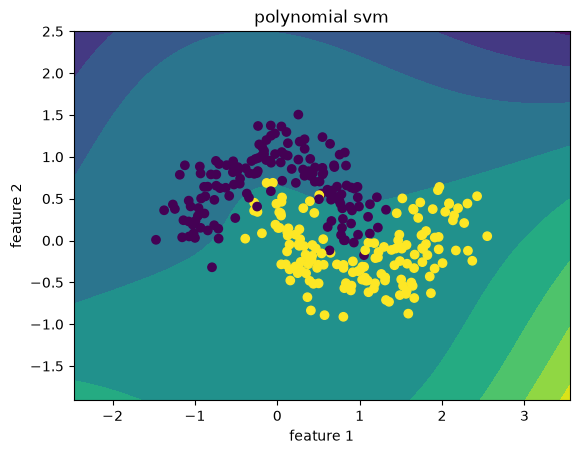

In [19]:
from sklearn.inspection import DecisionBoundaryDisplay
disp=DecisionBoundaryDisplay.from_estimator(model_svc,x)
plt.scatter(x[:,0],x[:,1],c=y)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("polynomial svm")
plt.show()

In [20]:
from sklearn.datasets import load_digits
data=load_digits(as_frame=True)
df=data.frame
df.head()


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


In [21]:
x = df.drop("target",axis=1)
y = df["target"]

In [22]:
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [23]:
from sklearn.naive_bayes import GaussianNB
model_nb = GaussianNB()

In [24]:
model_nb.fit(X_train,y_train)
y_pred_nb=model_nb.predict(X_test)

In [25]:
from sklearn.metrics import recall_score,precision_score
accuracy_nb = accuracy_score(y_test,y_pred_nb)
precision_nb = precision_score(y_test,y_pred_nb,average='macro')
recall_nb = recall_score(y_test,y_pred_nb,average='macro')
print(accuracy_nb)
print(precision_nb)
print(recall_nb)

0.8111111111111111
0.8462653634036693
0.8103410553410553


In [26]:
model_random2 = RandomForestClassifier()
model_random2.fit(X_train,y_train)
y_pred_random2= model_random2.predict(X_test)

In [27]:
accuracy_random2 = accuracy_score(y_test,y_pred_random2)
precision_random2 = precision_score(y_test,y_pred_random2,average='macro')
recall_random2 = recall_score(y_test,y_pred_random2,average='macro')
print(accuracy_random2)
print(precision_random2)
print(recall_random2)

0.9666666666666667
0.9678705578047684
0.9661904761904762


In [28]:
metric=pd.DataFrame({
    "model": ["GaussianNB","RandomForest"],
    "accuracy":[accuracy_nb,accuracy_random2],
    "precision":[precision_nb,precision_random2],
    "recall":[recall_nb,recall_random2]
})
metric

,model,accuracy,precision,recall
0,GaussianNB,0.811111,0.846265,0.810341
1,RandomForest,0.966667,0.967871,0.966190


In [29]:
from sklearn.datasets import load_wine
data= load_wine(as_frame=True)
df = data.frame
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [30]:
x= df.drop("target",axis=1)
y = df["target"]

In [31]:
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y)

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=5000)
logreg.fit(X_train_scaled, y_train)
y_pred_logreg = logreg.predict(X_test_scaled)
accuracy_log= accuracy_score(y_test,y_pred_logreg)

In [41]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=8)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
accuracy_knn = accuracy_score(y_test,y_pred_knn)

In [42]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=8, random_state=42)
tree.fit(X_train_scaled, y_train)
y_pred_tree = tree.predict(X_test_scaled)
accuracy_tree = accuracy_score(y_test,y_pred_tree)

In [43]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=200, random_state=42)
forest.fit(X_train_scaled, y_train)
y_pred_forest = forest.predict(X_test_scaled)
accuracy_forest = accuracy_score(y_test,y_pred_forest)

In [45]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train_scaled, y_train)
y_pred_ada = ada.predict(X_test_scaled)
accuracy_ada = accuracy_score(y_test,y_pred_ada)

In [46]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb.fit(X_train_scaled, y_train)
y_pred_gb = gb.predict(X_test_scaled)
accuracy_gb = accuracy_score(y_test,y_pred_gb)

In [47]:
from sklearn.svm import SVC

svm_rbf = SVC(kernel="rbf", C=1, gamma="scale")
svm_rbf.fit(X_train_scaled, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test_scaled)
accuracy_rbf = accuracy_score(y_test,y_pred_svm_rbf)

In [48]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
y_pred_nb = nb.predict(X_test_scaled)
accuracy_nb2= accuracy_score(y_test,y_pred_nb)

In [52]:
metric_all=pd.DataFrame({
    "model": ["LogisticRegression","knn","tree","RandomForest","ada","gb","svc","GaussianNB"],
    "accuracy":[accuracy_log,accuracy_knn,accuracy_tree,accuracy_forest,accuracy_ada,accuracy_gb,accuracy_svc,accuracy_nb2]
})
metric_all

,model,accuracy
0,LogisticRegression,0.972222
1,knn,0.944444
2,tree,0.888889
3,RandomForest,1.000000
4,ada,0.888889
5,gb,0.916667
6,svc,0.833333
7,GaussianNB,0.944444
